# Home Credit default risk: report notebook

This notebook follows the README with the tables and charts behind each statement. Small tables are computed here
from the processed data; results of long runs are read from `analysis_output/` (each file's script is listed in
`OUTPUTS.md`). Only aggregated numbers are shown: the competition data may not be redistributed.

The final model is **LightGBM v3, tuned, with loan price, monotone** (`lgbm_v3c_sh90_lr02_x3_tuned_mono`): feature
table v3c (716 v3 candidate columns plus 5 estimated loan-price columns), in-fold SHAP selection at 90% (about 290
columns per fold), no gender or family status, 4 tuned settings, learning rate 0.02, average of 3 fits, monotone
constraints on a list of 28 columns (14 of them survive the SHAP cut and are used). Earlier versions (v1, v2) are shown where the README tells their part of the story.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the repository root, so the project's own modules import
import pandas as pd
import io

import matplotlib.pyplot as plt
from IPython.display import Image, display

from homecredit import figures
from homecredit.data import read_raw
from homecredit.paths import Paths

P = Paths()
R = P.results
FINAL = "lgbm_v3c_sh90_lr02_x3_tuned_mono"
figures.use("v3m")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def show(fig):
    """Show a chart from homecredit/figures.py as a PNG image (the same rendering as the README files)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", facecolor=fig.get_facecolor())
    plt.close(fig)
    return Image(buf.getvalue())


def cmp(a, b, suffix=""):
    """One paired comparison file (experiments/compare.py)."""
    return pd.read_csv(R / "comparisons" / f"{a}_vs_{b}{suffix}.csv")

## 1. The data
Computed live from the Parquet copies of the Kaggle files.

In [2]:
tr = read_raw(P, "application_train", ["TARGET", "NAME_CONTRACT_TYPE"])
te = read_raw(P, "application_test", ["NAME_CONTRACT_TYPE"])
print(f"train applicants {len(tr):,}; test applicants {len(te):,}; "
      f"payment difficulties in train {100 * tr.TARGET.mean():.2f}%")
mix = pd.DataFrame({"train %": tr.NAME_CONTRACT_TYPE.value_counts(normalize=True) * 100,
                    "test %": te.NAME_CONTRACT_TYPE.value_counts(normalize=True) * 100}).round(2)
display(mix)

train applicants 307,511; test applicants 48,744; payment difficulties in train 8.07%


,train %,test %
NAME_CONTRACT_TYPE,,
Cash loans,90.48,99.1
Revolving loans,9.52,0.9


## 2. First findings: the test set is a different mix
Single columns that differ between train and test (EDA step 5), the loan-term detail, how well a model can tell
test rows from train rows (adversarial validation; v1 and the v3b table), and the estimated term and rate of the
loan applied for (`pipeline/make_features_rate.py`): test loans are shorter and dearer.

In [3]:
display(pd.read_csv(R / "eda" / "drift_details.csv"))
display(pd.read_csv(R / "eda" / "feature_drift_loan_terms.csv"))
for f in ["feature_adversarial_summary.csv", "feature_adversarial_summary_v3b.csv"]:
    adv = pd.read_csv(R / "eda" / f)
    display(adv[adv.model.isna()])
display(pd.read_csv(R / "features" / "rate_term_model.csv"))
display(pd.read_csv(R / "features" / "rate_drift.csv"))

,column,value,test,train
0,AMT_REQ_CREDIT_BUREAU_QRT,(missing),12.41,13.50
1,AMT_REQ_CREDIT_BUREAU_QRT,0.0,48.33,70.05
2,AMT_REQ_CREDIT_BUREAU_QRT,1.0,31.95,11.01
3,AMT_REQ_CREDIT_BUREAU_QRT,2.0,6.15,4.69
4,AMT_REQ_CREDIT_BUREAU_QRT,>2,1.16,0.75
5,NAME_CONTRACT_TYPE,Cash loans,99.10,90.48
6,NAME_CONTRACT_TYPE,Revolving loans,0.90,9.52


,feature,statistic,train_cash,test_cash
0,annuity_to_credit,quantile 0.05,0.0287,0.0324
1,annuity_to_credit,quantile 0.1,0.0293,0.0378
2,annuity_to_credit,quantile 0.25,0.0359,0.0485
3,annuity_to_credit,quantile 0.5,0.0484,0.0616
4,annuity_to_credit,quantile 0.75,0.0668,0.0795
5,annuity_to_credit,quantile 0.9,0.0978,0.1053
6,annuity_to_credit,quantile 0.95,0.1055,0.1093
7,credit_to_goods,quantile 0.05,1.0000,1.0000
8,credit_to_goods,quantile 0.1,1.0000,1.0000
9,credit_to_goods,quantile 0.25,1.0000,1.0000


,measure,model,scope,value
0,"adversarial AUC, mean of 5 folds",NaN,NaN,0.95688
1,"adversarial AUC, sd of 5 folds",NaN,NaN,0.00067
2,effective sample size of weights (train rows),NaN,NaN,9506.44496
3,"effective sample size, % of train",NaN,NaN,3.09142
4,largest weight (mean = 1),NaN,NaN,1556.58858


,measure,model,scope,value
0,"adversarial AUC, mean of 5 folds",NaN,NaN,0.98236
1,"adversarial AUC, sd of 5 folds",NaN,NaN,0.00042
2,effective sample size of weights (train rows),NaN,NaN,2046.58775
3,"effective sample size, % of train",NaN,NaN,0.66553
4,largest weight (mean = 1),NaN,NaN,3364.00364


,rows_fit,rows_holdout,trees,mae_months,median_abs_error_months,share_within_3_months_pct,r2,mae_if_always_median
0,369264,92245,3000,0.3,0.03,97.8,0.9948,13.74


,column,missing_train_pct,missing_test_pct,train_q10,train_q50,train_q90,test_q10,test_q50,test_q90
0,rate_term_pred,9.5,0.9,12.038,35.999,59.991,12.001,25.651,47.615
1,rate_yearly_pred,9.5,1.0,0.271,0.398,0.681,0.343,0.556,0.978
2,rate_total_cost,9.5,0.9,0.280,0.659,1.027,0.267,0.658,0.923
3,rate_vs_prev,15.1,3.5,-0.466,-0.097,0.285,-0.330,0.041,0.425
4,rate_term_vs_prev,59.4,54.1,0.666,1.449,3.333,0.528,1.136,2.643


## 3. Validation and noise
5 stratified folds x 5 seeds. `fold_sd` is how much one fold's AUC moves; the paired rule (gain over twice its
bootstrap SE and at least 18 of 25 wins) is applied in `experiments/compare.py`. Settings chosen on seed 1 are
judged on seeds 0, 2, 3 and 4 only (files ending in `_seeds0234`, at least 15 of 20 wins).

In [4]:
display(pd.read_csv(R / "validation" / "noise_summary.csv"))

,model,scope,mean_auc,fold_sd,seed_sd,seed_mean_min,seed_mean_max
0,logreg,all,0.73730,0.00236,0.00004,0.73724,0.73733
1,logreg,cash,0.73588,0.00236,0.00004,0.73581,0.73592
2,rule,all,0.71647,0.00279,0.00001,0.71646,0.71648
3,rule,cash,0.71635,0.00263,0.00001,0.71634,0.71635


## 4. Results: every model

,model,family,features,sensitive_columns_used,folds,cv_auc_all,cv_auc_cash,note
0,rule,"rule, no training",1 - mean of EXT_SOURCE_1/2/3,no,25,0.71647,0.71635,baseline
1,logreg_baseline,logistic regression,15 hand-picked application columns,gender,25,0.73730,0.73588,baseline
2,scorecard_app,WOE scorecard,application form only,gender + family,25,0.74327,0.74159,NaN
3,scorecard_full_no_gender,WOE scorecard,v1,no,25,0.75528,0.75420,explainable comparison
4,scorecard_full,WOE scorecard,v1: form + 22 history summaries,gender,25,0.75647,0.75544,NaN
5,lgbm_v3b_sh90_noext_s1,LightGBM,"v3, SHAP 90%, without the 3 external scores",no,5,0.76776,0.76718,seed 1 only (exploratory)
6,mlp_v2_combo_s0,neural net (MLP),v2,no,5,0.76811,0.76739,seed 0 only (exploratory)
7,lgbm_v1_no_sensitive,LightGBM,v1 without age too,no (no age),25,0.77588,0.77537,fairness test
8,lgbm_v1_no_gender_family,LightGBM,v1,no,25,0.77732,0.77697,fairness test; v2 reference
9,lgbm_v2_ext,LightGBM,v1 + external-score combinations,no,25,0.77754,0.77709,feature test (no gain)


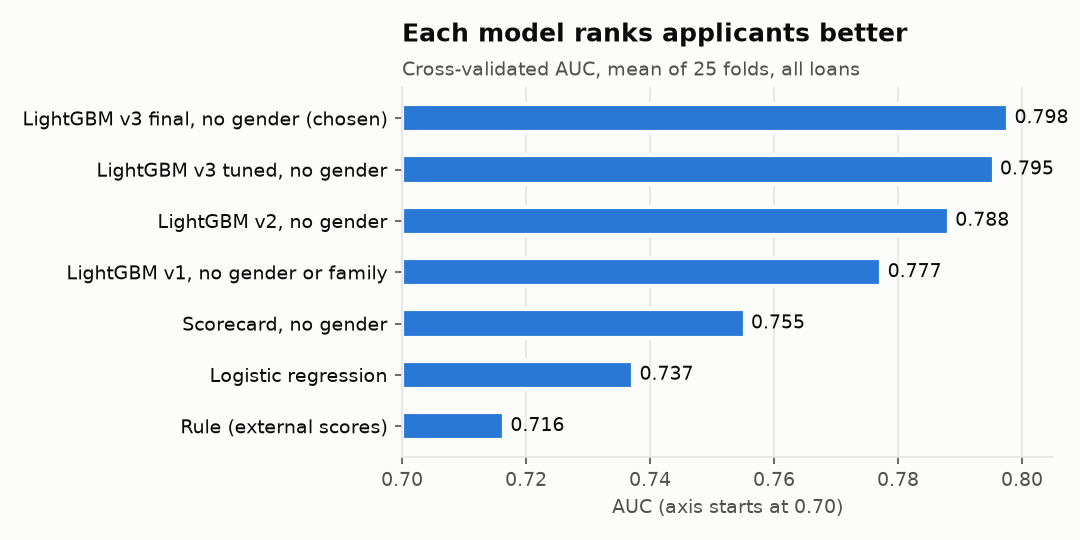

In [5]:
s = pd.read_csv(R / "model_summary_v3m.csv")
display(s[["model", "family", "features", "sensitive_columns_used", "folds", "cv_auc_all", "cv_auc_cash", "note"]])
show(figures.auc_by_model(P))

Each step of the main path, as paired comparisons (cash loans):

In [6]:
steps = [("logreg_baseline", "scorecard_app", ""), ("scorecard_app", "scorecard_full", ""),
         ("scorecard_full", "lgbm_v1", ""), ("lgbm_v1_no_gender_family", "lgbm_v2_combo", ""),
         ("lgbm_v2_combo", "lgbm_v2_combo_lr02", ""), ("lgbm_v2_combo_lr02", "lgbm_v2_combo_lr02_x3", ""),
         ("lgbm_v2_combo_lr02_x3", "lgbm_v3b_sh90_lr02_x3", ""),
         ("lgbm_v3b_sh90_lr02_x3", "lgbm_v3b_sh90_lr02_x3_tuned", "_seeds0234"),
         ("lgbm_v3b_sh90_lr02_x3_tuned", "lgbm_v3c_sh90_lr02_x3_tuned", "_seeds0234"),
         ("lgbm_v3c_sh90_lr02_x3_tuned", FINAL, "")]
display(pd.concat([cmp(a, b, x).query("scope == 'cash'") for a, b, x in steps], ignore_index=True))

,a,b,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_25,verdict,b_wins_of_20
0,logreg_baseline,scorecard_app,cash,0.73588,0.74159,0.00571,0.00063,25.0,B better (beats noise),NaN
1,scorecard_app,scorecard_full,cash,0.74159,0.75544,0.01385,0.00060,25.0,B better (beats noise),NaN
2,scorecard_full,lgbm_v1,cash,0.75544,0.77879,0.02335,0.00079,25.0,B better (beats noise),NaN
3,lgbm_v1_no_gender_family,lgbm_v2_combo,cash,0.77697,0.78451,0.00754,0.00059,25.0,B better (beats noise),NaN
4,lgbm_v2_combo,lgbm_v2_combo_lr02,cash,0.78451,0.78625,0.00174,0.00031,25.0,B better (beats noise),NaN
5,lgbm_v2_combo_lr02,lgbm_v2_combo_lr02_x3,cash,0.78625,0.78771,0.00147,0.00017,25.0,B better (beats noise),NaN
6,lgbm_v2_combo_lr02_x3,lgbm_v3b_sh90_lr02_x3,cash,0.78771,0.79313,0.00542,0.00047,25.0,B better (beats noise),NaN
7,lgbm_v3b_sh90_lr02_x3,lgbm_v3b_sh90_lr02_x3_tuned,cash,0.79311,0.79484,0.00174,0.00019,NaN,"B better (beats noise) [seeds 0,2,3,4: 20 pairs]",20.0
8,lgbm_v3b_sh90_lr02_x3_tuned,lgbm_v3c_sh90_lr02_x3_tuned,cash,0.79484,0.79764,0.00280,0.00035,NaN,"B better (beats noise) [seeds 0,2,3,4: 20 pairs]",20.0
9,lgbm_v3c_sh90_lr02_x3_tuned,lgbm_v3c_sh90_lr02_x3_tuned_mono,cash,0.79768,0.79744,-0.00024,0.00013,3.0,no clear difference,NaN


Choices inside v3, all on seed 1 (exploratory, 5 folds): the SHAP share (smallest share within noise of all
columns, rule fixed beforehand), the tuning search (20 random trials plus the current settings as trial 0), and the
model without the three external scores.

In [7]:
display(pd.concat([cmp("lgbm_v3b_all_s1", f"lgbm_v3b_sh{k}_s1") for k in (90, 95, 99)], ignore_index=True))
display(pd.read_csv(R / "tuning" / "v3b_sh90_trials.csv").sort_values("auc_all", ascending=False))
display(cmp("lgbm_v3b_sh90_s1", "lgbm_v3b_sh90_noext_s1"))

,a,b,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_5,verdict
0,lgbm_v3b_all_s1,lgbm_v3b_sh90_s1,all,0.78999,0.79016,0.00017,0.00035,3,no clear difference [exploratory: 5 pairs]
1,lgbm_v3b_all_s1,lgbm_v3b_sh90_s1,cash,0.78929,0.78951,0.00023,0.00038,4,no clear difference [exploratory: 5 pairs]
2,lgbm_v3b_all_s1,lgbm_v3b_sh95_s1,all,0.78999,0.79080,0.00081,0.00036,5,B better (beats noise) [exploratory: 5 pairs]
3,lgbm_v3b_all_s1,lgbm_v3b_sh95_s1,cash,0.78929,0.79025,0.00096,0.00038,5,B better (beats noise) [exploratory: 5 pairs]
4,lgbm_v3b_all_s1,lgbm_v3b_sh99_s1,all,0.78999,0.79055,0.00056,0.00036,4,no clear difference [exploratory: 5 pairs]
5,lgbm_v3b_all_s1,lgbm_v3b_sh99_s1,cash,0.78929,0.78989,0.00060,0.00040,4,no clear difference [exploratory: 5 pairs]


,trial,num_leaves,min_child_samples,feature_fraction,lambda_l2,auc_all,auc_cash,auc_all_min_fold,trees_median,seconds
17,17,30,174,0.240,6.7041,0.79285,0.79214,0.78613,500,34
12,12,36,351,0.259,0.7406,0.79206,0.79134,0.78626,392,44
6,6,17,30,0.569,0.8741,0.79188,0.79115,0.78652,691,69
18,18,34,28,0.540,6.0459,0.79170,0.79099,0.78395,372,44
15,15,41,260,0.261,0.0143,0.79157,0.79110,0.78573,379,53
13,13,19,292,0.651,0.0523,0.79150,0.79092,0.78496,553,96
9,9,21,204,0.468,0.0853,0.79127,0.79042,0.78480,475,42
19,19,40,432,0.450,0.1887,0.79091,0.79015,0.78545,290,38
16,16,37,38,0.164,0.5508,0.79075,0.79008,0.78387,530,32
7,7,58,69,0.798,8.7600,0.79054,0.78995,0.78438,314,98


,a,b,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_5,verdict
0,lgbm_v3b_sh90_s1,lgbm_v3b_sh90_noext_s1,all,0.79016,0.76776,-0.02240,0.00087,0,A better (beats noise) [exploratory: 5 pairs]
1,lgbm_v3b_sh90_s1,lgbm_v3b_sh90_noext_s1,cash,0.78951,0.76718,-0.02233,0.00085,0,A better (beats noise) [exploratory: 5 pairs]


Is the loan-price gain smaller on test-like applicants? (`experiments/test_like_gain.py`; out-of-fold, no
model trained.)

In [8]:
display(pd.read_csv(R / "comparisons" /
                    "test_like_gain_lgbm_v3b_sh90_lr02_x3_tuned_vs_lgbm_v3c_sh90_lr02_x3_tuned.csv"))

,part,applicants,default_rate_pct,auc_a,auc_b,gain_mean,gain_sd_over_seeds,seeds
0,all loans,307511,8.07,0.79542,0.79801,0.00259,0.00016,5
1,short cash loans (predicted term <= 24 months),76333,7.55,0.80916,0.81139,0.00224,0.00016,5
2,20% most test-like (adversarial v1),61503,7.62,0.79212,0.79440,0.00228,0.00030,5
3,rest (neither),196588,8.43,0.79247,0.79530,0.00283,0.00018,5


## 5. Monotone constraints
Share of 20,000 training applicants whose predicted risk goes DOWN after one small step the worse way on a column
with a business direction (`experiments/monotone_check.py`, final models trained on all of train). Only the 14
listed columns that the final model uses are checked; related columns that were not on the list stay
unconstrained.

In [9]:
v = pd.read_csv(R / "monotone_v3c" / "violations.csv")
display(v.groupby("model").pct_risk_down_after_worse_value.agg(["count", "mean", "median", "max"]).round(2))
display(v.pivot(index="column", columns="model", values="pct_risk_down_after_worse_value"))

,count,mean,median,max
model,,,,
lgbm_v3c_sh90_lr02_x3_tuned,14,10.14,6.52,38.44
lgbm_v3c_sh90_lr02_x3_tuned_mono,14,0.00,0.00,0.00


model,lgbm_v3c_sh90_lr02_x3_tuned,lgbm_v3c_sh90_lr02_x3_tuned_mono
column,,
EXT_SOURCE_1,0.58,0.0
EXT_SOURCE_2,0.58,0.0
EXT_SOURCE_3,1.26,0.0
annuity_to_income,16.23,0.0
employed_years,6.58,0.0
inst_days_late_mean,12.32,0.0
inst_late_share,15.14,0.0
inst_late_share_last_year,6.46,0.0
prev_refused_share,2.64,0.0


## 6. The independent check: Kaggle late submissions
Scores typed from the Kaggle submissions page (`analysis_output/kaggle/kaggle_scores*.csv`). Nothing was chosen or
changed because of them. `private_minus_cv_cash` moves from about +0.001 (v1) to -0.0011 (v3b tuned) and then to
-0.0029 when the loan price is added (final model -0.0030). The cause is unknown; optimism from many choices on the
same folds is one guess, but the loan price was one planned idea. The hidden-test score is the better estimate of
the level.

,model,private_auc,public_auc,cv_auc_all,cv_auc_cash,private_minus_cv_cash,public_minus_private
0,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,0.79709,0.79990,0.79957,0.79929,-0.00220,0.00281
1,lgbm_v3c_sh90_lr02_x3_tuned,0.79479,0.79596,0.79802,0.79768,-0.00289,0.00117
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,0.79448,0.79593,0.79779,0.79744,-0.00296,0.00145
3,lgbm_v3b_sh90_lr02_x3_tuned,0.79371,0.79562,0.79544,0.79485,-0.00114,0.00191
4,lgbm_v3b_sh90_lr02_x3,0.79261,0.79405,0.79382,0.79313,-0.00052,0.00144
5,lgbm_v3b_sh90_with_gender,0.79097,0.79546,0.79201,0.79140,-0.00043,0.00449
6,lgbm_v3b_sh99_s1,0.79047,0.78861,0.79055,0.78989,0.00058,-0.00186
7,lgbm_v3b_sh90,0.78888,0.79062,0.79026,0.78963,-0.00075,0.00174
8,lgbm_v3b_all_s1,0.78921,0.79095,0.78999,0.78929,-0.00008,0.00174
9,lgbm_v2_combo_lr02_x3,0.78782,0.78971,0.78823,0.78771,0.00011,0.00189


,reference,change,cv_gain_cash,private_gain,public_gain,rough_se_private,private_gain_over_2se,same_sign_as_cv
0,lgbm_v1,lgbm_v1_no_gender,-0.00153,-0.00148,0.00043,0.00096,False,True
1,lgbm_v1,lgbm_v1_no_gender_family,-0.00182,-0.00222,-0.00147,0.00110,True,True
2,lgbm_v1_no_gender_family,lgbm_v2_win,0.00262,0.00150,0.00152,0.00128,False,True
3,lgbm_v1_no_gender_family,lgbm_v2_stk_nobb,0.00366,0.00435,0.00044,0.00123,True,True
4,lgbm_v1_no_gender_family,lgbm_v2_term,0.00326,0.00312,0.00136,0.00123,True,True
5,lgbm_v2_stk_nobb,lgbm_v2_stk,0.00022,0.00173,0.00244,0.00099,False,True
6,lgbm_v1_no_gender_family,lgbm_v2_combo,0.00754,0.00681,0.00453,0.00158,True,True
7,lgbm_v2_combo_with_gender,lgbm_v2_combo,-0.00163,-0.00341,-0.00063,0.00104,True,True
8,lgbm_v2_combo,lgbm_v2_combo_lr02,0.00174,0.00226,0.00137,0.00083,True,True
9,lgbm_v2_combo_lr02,lgbm_v2_combo_lr02_x3,0.00146,0.00103,0.00031,0.00045,True,True


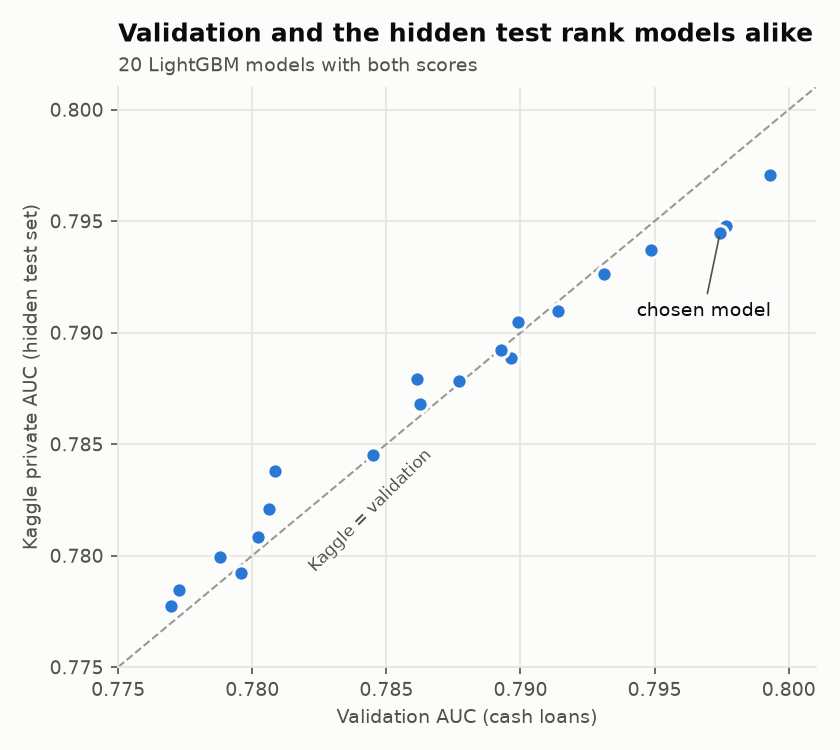

In [10]:
display(pd.read_csv(R / "kaggle" / "kaggle_vs_cv_v3m.csv"))
display(pd.read_csv(R / "kaggle" / "kaggle_steps_v3m.csv"))
show(figures.cv_vs_kaggle(P))

## 7. Calibration
ECE = average gap between predicted and observed, in points. Measured inside each validation fold and compared with
the value a perfectly calibrated model would show (`floor_pts`); the pooled ECE in `summary_v3m.csv` flatters the
cross-fitted isotonic correction.

,model,version,scope,ece_by_fold_pts,floor_pts
0,lgbm_v3c_sh90_lr02_x3_tuned_mono,raw,all,0.4701,0.3384
1,lgbm_v3c_sh90_lr02_x3_tuned_mono,raw,cash,0.4809,0.3594
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,platt,all,0.4641,0.3400
3,lgbm_v3c_sh90_lr02_x3_tuned_mono,platt,cash,0.4745,0.3614
4,lgbm_v3c_sh90_lr02_x3_tuned_mono,isotonic,all,0.3628,0.3330
5,lgbm_v3c_sh90_lr02_x3_tuned_mono,isotonic,cash,0.3774,0.3591


,model,version,scope,auc,mean_pred_pct,observed_pct,slope,brier,log_loss
0,lgbm_v3c_sh90_lr02_x3_tuned_mono,raw,all,0.797777,7.978326,8.072882,1.014952,0.065140,0.233433
1,lgbm_v3c_sh90_lr02_x3_tuned_mono,raw,cash,0.797426,8.258493,8.345913,1.011764,0.066958,0.238765
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,platt,all,0.797762,8.072601,8.072882,0.999669,0.065146,0.233425
3,lgbm_v3c_sh90_lr02_x3_tuned_mono,platt,cash,0.797411,8.358943,8.345913,0.996513,0.066965,0.238762
4,lgbm_v3c_sh90_lr02_x3_tuned_mono,isotonic,all,0.797157,8.073270,8.072882,0.993643,0.065137,0.233460
5,lgbm_v3c_sh90_lr02_x3_tuned_mono,isotonic,cash,0.796820,8.359598,8.345913,0.992669,0.066958,0.238817


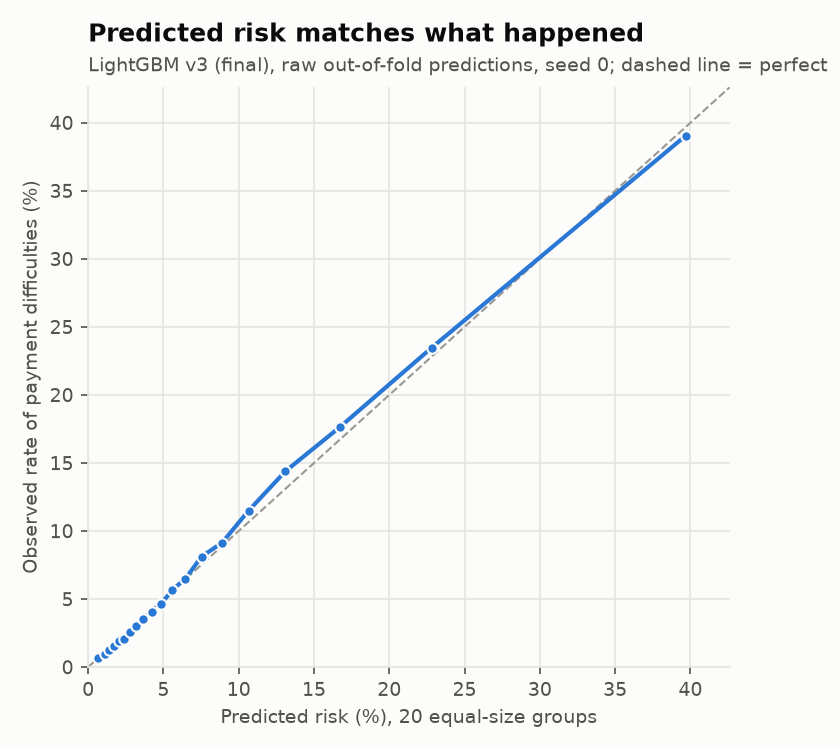

In [11]:
display(pd.read_csv(R / "calibration" / "ece_by_fold_v3m.csv"))
c = pd.read_csv(R / "calibration" / "summary_v3m.csv")
display(c[["model", "version", "scope", "auc", "mean_pred_pct", "observed_pct", "slope", "brier", "log_loss"]])
show(figures.calibration(P))

## 8. What the model relies on (global SHAP)
Final model, 20,000 training applicants (`analysis/global_shap.py`). Share of total mean |SHAP| per reason group,
the largest columns with the direction of their effect (Spearman correlation of value and SHAP), and the mean SHAP
per decile of the largest numeric columns. The group share adds up each column's mean |SHAP|, which favours groups
with many related columns (see the `columns` count); read the shares as rough.

,group,columns,mean_abs_shap,share_pct
0,External credit scores,3,0.656526,16.8
1,Loans with other lenders,70,0.644836,16.5
2,Earlier Home Credit applications,93,0.605632,15.5
3,Repayment of earlier Home Credit loans,55,0.580233,14.8
4,Loan size and terms vs income,15,0.567494,14.5
5,Employment and income type,5,0.265475,6.8
6,Credit card use,12,0.095513,2.4
7,Region and address,4,0.066411,1.7
8,Car ownership,1,0.062624,1.6
9,Documents and ID,4,0.058142,1.5


,column,group,mean_abs_shap,share_pct,direction_spearman
0,EXT_SOURCE_2,External credit scores,0.288300,7.37,-1.00
1,EXT_SOURCE_3,External credit scores,0.219872,5.62,-0.99
2,rate_total_cost,Loan size and terms vs income,0.163782,4.19,0.97
3,EXT_SOURCE_1,External credit scores,0.148355,3.79,-0.98
4,rate_yearly_pred,Loan size and terms vs income,0.128737,3.29,0.95
5,ORGANIZATION_TYPE,Employment and income type,0.083817,2.14,NaN
6,term_down_payment,Loan size and terms vs income,0.073598,1.88,-0.96
7,AMT_ANNUITY,Loan size and terms vs income,0.071621,1.83,0.93
8,OCCUPATION_TYPE,Employment and income type,0.065223,1.67,NaN
9,employed_years,Employment and income type,0.063828,1.63,-0.97


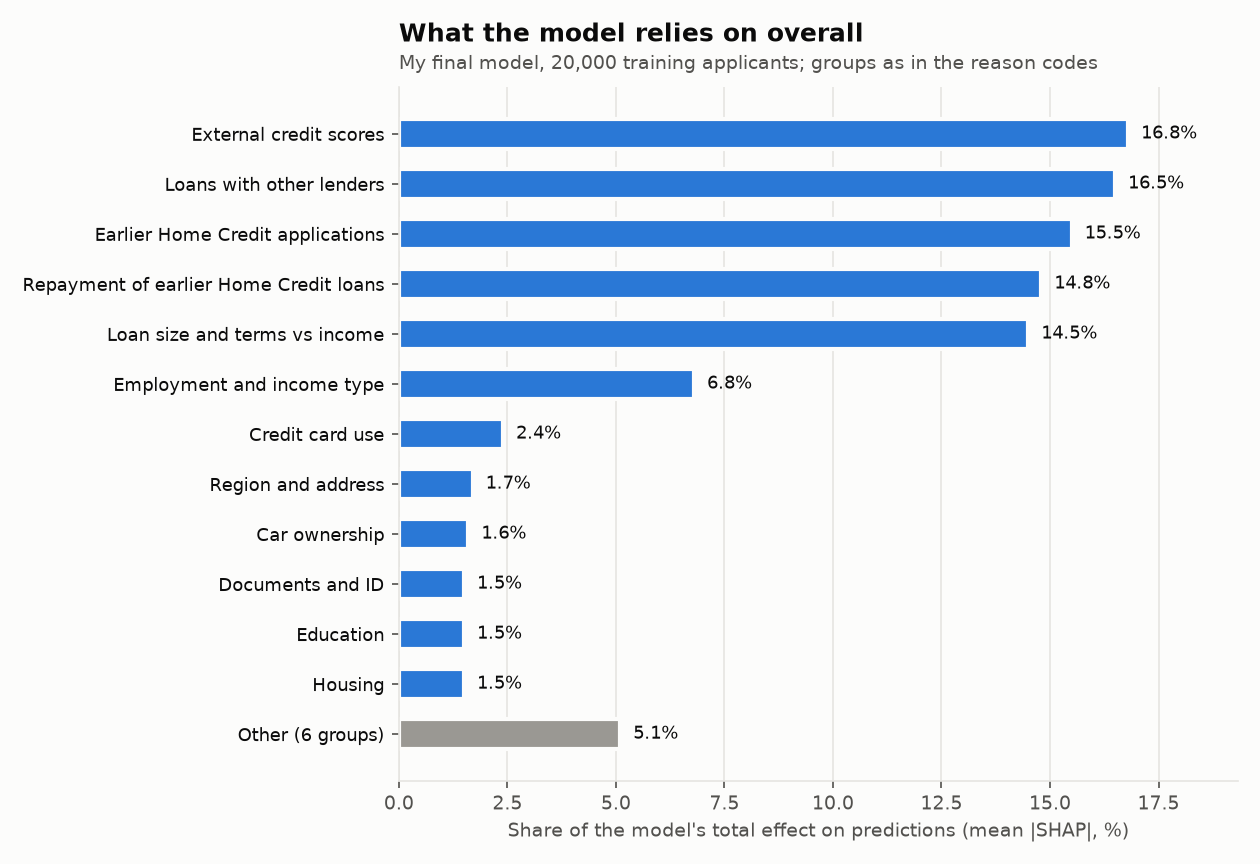

In [12]:
display(pd.read_csv(R / "global_shap_v3m" / "groups.csv"))
display(pd.read_csv(R / "global_shap_v3m" / "top_columns.csv"))
show(figures.shap_groups(P))

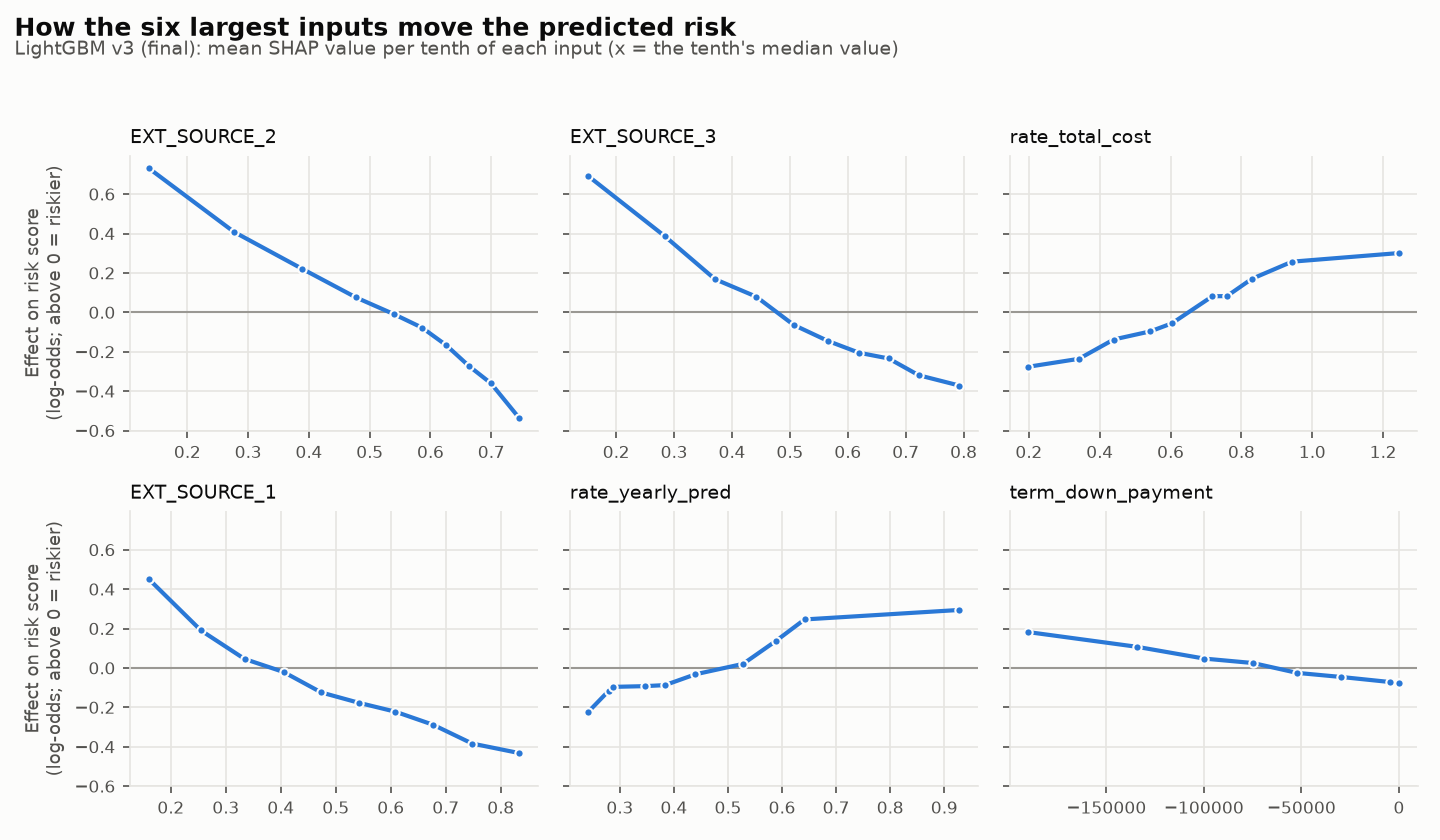

In [13]:
show(figures.shap_dependence(P))

## 9. Reason codes
At a cut-off that declines about 6%. Top-3 reason groups per declined applicant (SHAP for LightGBM; points below
the approved average for the scorecard), and the counterfactual test: replace one reason group with an approved
applicant's values and re-score. `top4` (the next reason) is a closer control than a random unused group.

,model,reason_group,pct_declines_top1,pct_declines_in_top3
0,lightgbm (SHAP),External credit scores,64.60,87.72
1,lightgbm (SHAP),Loan size and terms vs income,17.53,64.41
2,lightgbm (SHAP),Repayment of earlier Home Credit loans,6.60,35.33
3,lightgbm (SHAP),Loans with other lenders,4.04,43.74
4,lightgbm (SHAP),Credit card use,3.99,16.07
5,lightgbm (SHAP),Earlier Home Credit applications,2.84,31.21
6,lightgbm (SHAP),Employment and income type,0.40,19.50
7,lightgbm (SHAP),Age [sensitive],0.00,0.07


,rank,tested,mean_risk_drop_pts,flip_to_approve_pct,folds_where_top_beats_next
0,top1,17710.0,19.268916,80.726143,5.0
1,top2,17710.0,12.274070,59.431959,5.0
2,top3,17710.0,8.504182,44.508187,5.0
3,control,17710.0,0.690899,7.911914,NaN
4,top4,17710.0,5.932540,33.088650,5.0


,model,flag,pct_declines_top1,pct_declines_any_top3
0,lightgbm (SHAP),"sensitive (age, gender, family)",0.0,0.07
1,lightgbm (SHAP),"not a fair reason (application day/hour, conta...",0.0,0.11
2,scorecard (points below max),"sensitive (age, gender, family)",0.0,0.00
3,scorecard (points below max),"not a fair reason (application day/hour, conta...",0.0,0.00
4,scorecard (points below approved average),"sensitive (age, gender, family)",0.0,0.00
5,scorecard (points below approved average),"not a fair reason (application day/hour, conta...",0.0,0.08


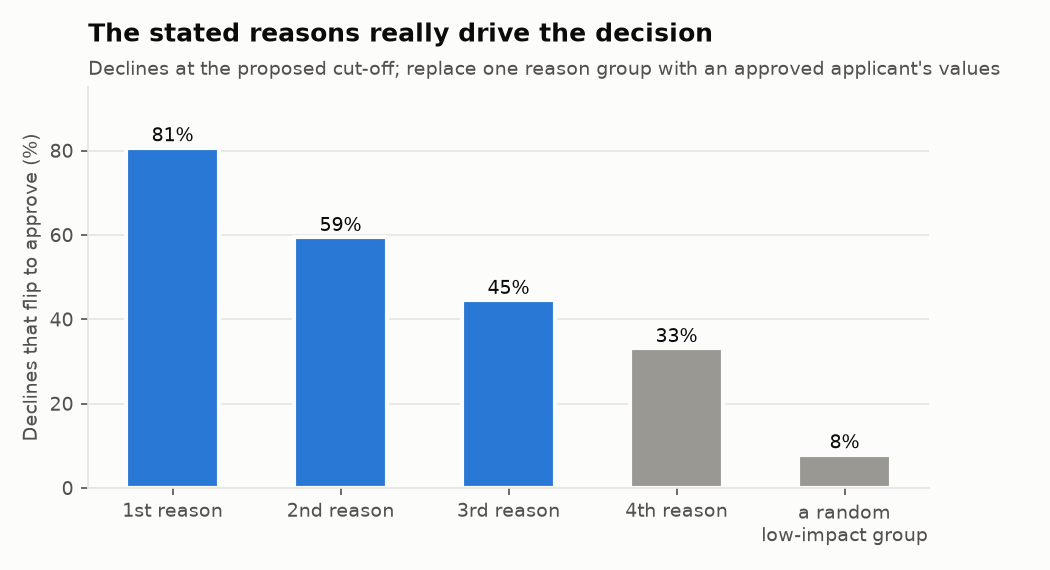

In [14]:
rs = pd.read_csv(R / "reasons_v3m_cut06" / "top_reason_share.csv")
display(rs[rs.model == "lightgbm (SHAP)"].head(8))
display(pd.read_csv(R / "reasons_v3m_cut06" / "counterfactual_summary.csv"))
display(pd.read_csv(R / "reasons_v3m_cut06" / "sensitive_reasons.csv"))
show(figures.reason_counterfactual(P))

## 10. Error analysis (final model)
AUC inside each group and its share of the wrongly ordered pairs; a `missed_ratio` above 1 means the group's
defaulters cost more than their share.

In [15]:
seg = pd.read_csv(R / "errors_v3m" / "segments.csv")
display(seg[seg.segment.isin(["age band", "income type", "loan term band (annuity / credit quintile)"])][
    ["segment", "group", "applicants", "default_rate_pct", "auc_within", "missed_ratio", "false_alarm_ratio"]])
display(pd.read_csv(R / "validation" / "duplicate_check.csv"))

,segment,group,applicants,default_rate_pct,auc_within,missed_ratio,false_alarm_ratio
2,income type,Commercial associate,71617,7.48,0.7951,1.06,0.95
3,income type,Other,55,18.18,0.8747,0.25,1.00
4,income type,Pensioner,55362,5.39,0.7691,1.52,0.69
5,income type,State servant,21703,5.75,0.7977,1.32,0.73
6,income type,Working,158774,9.59,0.7958,0.85,1.18
7,age band,25-34,72429,10.66,0.7897,0.75,1.32
8,age band,35-44,84261,8.41,0.8009,0.98,1.01
9,age band,45-54,70190,7.05,0.7972,1.12,0.89
10,age band,55-64,60522,5.42,0.7698,1.50,0.70
11,age band,65+,7876,3.66,0.7684,2.12,0.41


,measure,value
0,train rows in a repeated pseudo-person group,12411.00000
1,repeated groups,5991.00000
2,repeated groups split across seed-0 folds,4871.00000
3,"pairs where both defaulted, % (observed)",1.10900
4,"pairs where both defaulted, % (if independent)",0.45300
5,"AUC usual folds, all rows",0.78432
6,"AUC grouped folds, all rows",0.78555
7,"AUC grouped minus usual, all rows",0.00123
8,"AUC usual folds, rows in a repeated group",0.77440
9,"AUC grouped folds, rows in a repeated group",0.77480


## 11. Fairness
Accuracy cost of leaving gender and family out at the final setting; approval gaps at a stricter rule (decline the
riskiest 15%); proxies (how well the final model's candidate columns reveal each attribute); and the direct effect
of age and gender at a 6% decline rule. The direct test was measured on the untuned v3 setting (fairness_v3), not
on the final model. These tables use the raw model scores. Approval by group at the break-even rule is in
section 12, where predicted risks are the calibrated (isotonic) probabilities used for money.

In [16]:
display(pd.read_csv(R / "fairness_v3m" / "accuracy_cost.csv").query("scope == 'cash'"))
display(pd.read_csv(R / "fairness_v3m" / "disparity_summary.csv"))
display(pd.read_csv(R / "fairness_v3m" / "proxy_check.csv"))
display(pd.read_csv(R / "fairness_v3" / "counterfactual_age_gender.csv"))

,reference,variant,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_25,verdict
1,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,lgbm_v3c_sh90_lr02_x3_tuned_mono,cash,0.79929,0.79744,-0.00185,0.00021,0,A better (beats noise)


,model,attribute,lowest_group,lowest_approval_pct,highest_group,highest_approval_pct,approval_ratio_low_high,good_payer_approval_gap_pts,max_calibration_gap_pts
0,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,gender,M,79.22,F,88.00,0.900,7.28,0.27
1,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,age band,<25,70.28,65+,97.82,0.718,23.55,0.30
2,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,family status,Civil marriage,79.97,Widow,92.16,0.868,9.76,0.28
3,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,children,3+,79.08,0,86.05,0.919,5.86,0.29
4,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,education,Lower secondary,78.35,Higher education,92.44,0.848,11.67,0.55
5,lgbm_v3c_sh90_lr02_x3_tuned_mono_with_gender,region rating,3,76.79,1,93.66,0.820,13.57,0.32
6,lgbm_v3c_sh90_lr02_x3_tuned_mono,gender,M,80.72,F,87.22,0.925,5.22,0.79
7,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,<25,70.17,65+,97.92,0.717,23.75,0.30
8,lgbm_v3c_sh90_lr02_x3_tuned_mono,family status,Civil marriage,81.42,Widow,92.07,0.884,8.35,0.84
9,lgbm_v3c_sh90_lr02_x3_tuned_mono,children,3+,78.33,0,86.20,0.909,6.68,0.30


,attribute,rows,share_positive_pct,columns_used,proxy_auc
0,gender: men vs women,307507,34.16,721,0.9132
1,family: married or civil marriage,307511,73.56,721,0.7584
2,age: under 25,307511,3.98,719,0.9942
3,age: 55 or over,307511,22.24,719,0.9726


,change,group,applicants,declined_pct,declined_after_change_pct,decisions_changed_pct,mean_risk_change_pts,max_abs_diff_vs_saved_oof,attribute_columns_kept
0,age (model without gender/family),all,307511,5.64,6.10,0.78,0.273,0.0,2/2/2/2/2
1,age (model without gender/family),25-34,72429,9.36,10.03,1.27,0.294,0.0,2/2/2/2/2
2,age (model without gender/family),35-44,84261,5.80,5.65,0.32,-0.126,0.0,2/2/2/2/2
3,age (model without gender/family),45-54,70190,4.17,4.51,0.40,0.258,0.0,2/2/2/2/2
4,age (model without gender/family),55-64,60522,2.09,2.51,0.52,0.452,0.0,2/2/2/2/2
5,age (model without gender/family),65+,7876,0.48,0.70,0.24,0.153,0.0,2/2/2/2/2
6,age (model without gender/family),<25,12233,11.76,16.35,4.80,2.170,0.0,2/2/2/2/2
7,gender (model with gender/family),all,307511,5.73,6.09,1.92,0.526,0.0,1/1/1/1/1
8,gender (model with gender/family),F,202448,4.38,6.04,1.73,1.572,0.0,1/1/1/1/1
9,gender (model with gender/family),M,105059,8.34,6.19,2.29,-1.490,0.0,1/1/1/1/1


## 12. Business: choosing the cut-off
Assumed margin 20% of the credit for a repaid loan, loss 60% for a loan with difficulties (not in the data).
Profit is a back-test on past (approved) applicants, in the data's (undisclosed) currency per applicant.
Probabilities are the cross-fitted isotonic ones. The tuning step's money difference (+30, interval -22 to 84) is in
`business_v3t/differences.csv`.

,model,policy,approval_pct,bad_rate_approved_pct,profit_per_applicant,profit_sd_seeds,profit_vs_approve_all
0,(no model),approve everyone,100.000,8.073,83782.158,0.00,0.0
1,lgbm_v3c_sh90_lr02_x3_tuned_mono,break-even rule,93.386,6.109,86632.746,18.56,2850.6
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,cross-fitted best cut-off,93.254,6.086,86612.873,34.06,2830.7
3,lgbm_v3c_sh90_lr02_x3_tuned,break-even rule,93.488,6.127,86644.979,44.41,2862.8
4,lgbm_v3c_sh90_lr02_x3_tuned,cross-fitted best cut-off,93.292,6.091,86635.772,45.51,2853.6
5,lgbm_v3b_sh90_lr02_x3_tuned,break-even rule,92.828,6.010,86564.464,21.41,2782.3
6,lgbm_v3b_sh90_lr02_x3_tuned,cross-fitted best cut-off,92.647,5.972,86566.748,16.03,2784.6
7,lgbm_v2_combo_lr02_x3,break-even rule,93.860,6.281,86350.874,27.52,2568.7
8,lgbm_v2_combo_lr02_x3,cross-fitted best cut-off,93.948,6.301,86340.269,36.46,2558.1
9,scorecard_full_no_gender,break-even rule,95.157,6.844,85170.144,18.15,1388.0


,policy_a,policy_b,profit_diff_per_applicant,ci95_low,ci95_high
0,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,(no model) / approve everyone,2850.6,2658.5,3034.2
1,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,scorecard_full_no_gender / break-even rule,1462.6,1316.7,1623.1
2,lgbm_v1_no_gender_family / break-even rule,scorecard_full_no_gender / break-even rule,811.4,693.0,944.6
3,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,lgbm_v1_no_gender_family / break-even rule,651.2,541.7,761.6
4,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,lgbm_v1 / break-even rule,577.7,467.4,695.5
5,lgbm_v3c_sh90_lr02_x3_tuned_mono / cross-fitte...,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,-19.9,-35.2,-4.4
6,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,lgbm_v3c_sh90_lr02_x3_tuned / break-even rule,-12.2,-46.0,21.2
7,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,lgbm_v3b_sh90_lr02_x3_tuned / break-even rule,68.3,-3.1,132.3
8,lgbm_v3c_sh90_lr02_x3_tuned_mono / break-even ...,lgbm_v2_combo_lr02_x3 / break-even rule,281.9,183.2,377.2


,margin,lgd,break_even_p,model,approval_pct,bad_rate_approved_pct,profit_per_applicant,profit_approve_all,profit_vs_approve_all
0,0.1,0.4,0.200,lgbm_v3c_sh90_lr02_x3_tuned_mono,89.604,5.429,40261.232,37388.2,2873.0
7,0.1,0.6,0.143,lgbm_v3c_sh90_lr02_x3_tuned_mono,82.895,4.521,35110.384,28382.4,6728.0
14,0.1,0.8,0.111,lgbm_v3c_sh90_lr02_x3_tuned_mono,76.608,3.852,31131.618,19376.7,11754.9
21,0.2,0.4,0.333,lgbm_v3c_sh90_lr02_x3_tuned_mono,96.841,6.922,93715.569,92787.9,927.7
28,0.2,0.6,0.250,lgbm_v3c_sh90_lr02_x3_tuned_mono,93.386,6.109,86632.746,83782.2,2850.5
35,0.2,0.8,0.200,lgbm_v3c_sh90_lr02_x3_tuned_mono,89.604,5.429,80522.463,74776.4,5746.1
42,0.3,0.4,0.429,lgbm_v3c_sh90_lr02_x3_tuned_mono,98.690,7.490,148598.103,148187.6,410.5
49,0.3,0.6,0.333,lgbm_v3c_sh90_lr02_x3_tuned_mono,96.858,6.928,140569.814,139181.9,1387.9
56,0.3,0.8,0.273,lgbm_v3c_sh90_lr02_x3_tuned_mono,94.674,6.381,133323.380,130176.1,3147.3


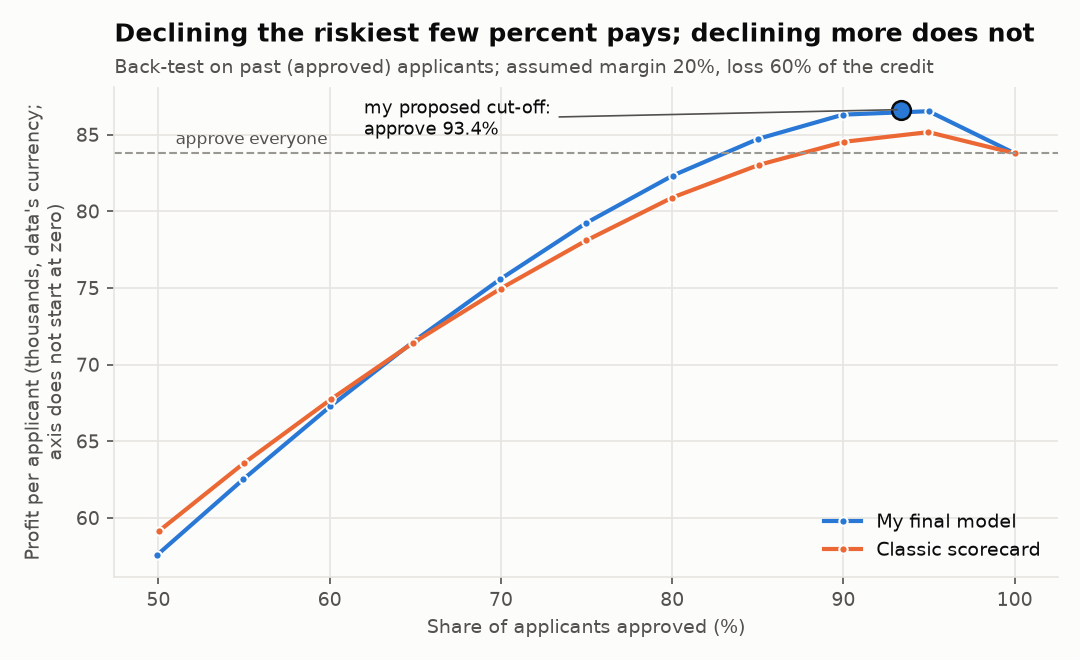

In [17]:
display(pd.read_csv(R / "business_v3m" / "policies.csv"))
display(pd.read_csv(R / "business_v3m" / "differences.csv"))
sens = pd.read_csv(R / "business_v3m" / "sensitivity.csv")
display(sens[sens.model == FINAL])
show(figures.profit_curve(P))

Score bands, KS, the swap-set between LightGBM and the scorecard, and population stability (PSI).

In [18]:
for f in ["score_bands", "ks", "swap_set", "psi"]:
    display(pd.read_csv(R / "credit_v3m" / f"{f}.csv"))

,model,band,risk_from_pct,risk_to_pct,applicants,difficulty_rate_pct,cum_approval_pct,cum_difficulty_rate_pct
0,lgbm_v3c_sh90_lr02_x3_tuned_mono,1,0.14,1.27,30752,0.78,10.0,0.78
1,lgbm_v3c_sh90_lr02_x3_tuned_mono,2,1.27,1.91,30751,1.36,20.0,1.07
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,3,1.91,2.61,30751,1.99,30.0,1.38
3,lgbm_v3c_sh90_lr02_x3_tuned_mono,4,2.61,3.45,30751,2.76,40.0,1.72
4,lgbm_v3c_sh90_lr02_x3_tuned_mono,5,3.45,4.54,30751,3.67,50.0,2.11
5,lgbm_v3c_sh90_lr02_x3_tuned_mono,6,4.54,6.01,30751,5.06,60.0,2.61
6,lgbm_v3c_sh90_lr02_x3_tuned_mono,7,6.01,8.17,30751,7.37,70.0,3.29
7,lgbm_v3c_sh90_lr02_x3_tuned_mono,8,8.17,11.75,30751,10.34,80.0,4.17
8,lgbm_v3c_sh90_lr02_x3_tuned_mono,9,11.75,19.12,30751,15.90,90.0,5.47
9,lgbm_v3c_sh90_lr02_x3_tuned_mono,10,19.12,91.41,30751,31.49,100.0,8.07


,model,ks_mean_of_seeds,ks_sd,ks_of_seed_mean_score
0,lgbm_v3c_sh90_lr02_x3_tuned_mono,0.4519,0.0007,0.4528
1,scorecard_full_no_gender,0.3824,0.0007,0.3837


,group,applicants,pct_of_applicants,difficulty_rate_pct
0,approved by both,281813,91.64,5.88
1,approved by LightGBM only,4967,1.62,18.20
2,approved by the scorecard only,10924,3.55,32.03
3,declined by both,9807,3.19,39.39


,what,psi
0,model score,0.0017
1,EXT_SOURCE_2,0.0151
2,EXT_SOURCE_3,0.0078
3,rate_total_cost,0.4469
4,rate_yearly_pred,0.8404
5,EXT_SOURCE_1,0.0846
6,ORGANIZATION_TYPE,0.0055
7,OCCUPATION_TYPE,0.0020
8,agg_bur_debt_ratio_max,0.0050
9,agg_bur_act_debt_ratio_max,0.0087


,model,attribute,group,applicants,default_rate_pct,mean_pred_pct,approval_pct,approval_pct_good_payers,default_rate_approved_pct,adverse_impact_ratio
0,lgbm_v3c_sh90_lr02_x3_tuned_mono,gender,F,202448,7.00,7.34,94.56,96.19,5.40,1.000
1,lgbm_v3c_sh90_lr02_x3_tuned_mono,gender,M,105059,10.14,9.49,91.13,93.78,7.53,0.964
2,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,25-34,72429,10.66,10.75,89.10,92.19,7.56,0.896
3,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,35-44,84261,8.41,8.20,93.15,95.25,6.35,0.937
4,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,45-54,70190,7.05,7.10,95.07,96.62,5.53,0.956
5,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,55-64,60522,5.42,5.47,97.48,98.26,4.67,0.981
6,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,65+,7876,3.66,3.32,99.41,99.62,3.45,1.000
7,lgbm_v3c_sh90_lr02_x3_tuned_mono,age band,<25,12233,12.29,12.83,86.59,89.74,9.10,0.871
8,lgbm_v3c_sh90_lr02_x3_tuned_mono,family status,Civil marriage,29775,9.94,9.28,91.40,94.14,7.25,0.943
9,lgbm_v3c_sh90_lr02_x3_tuned_mono,family status,Married,196432,7.56,7.90,93.67,95.53,5.72,0.967


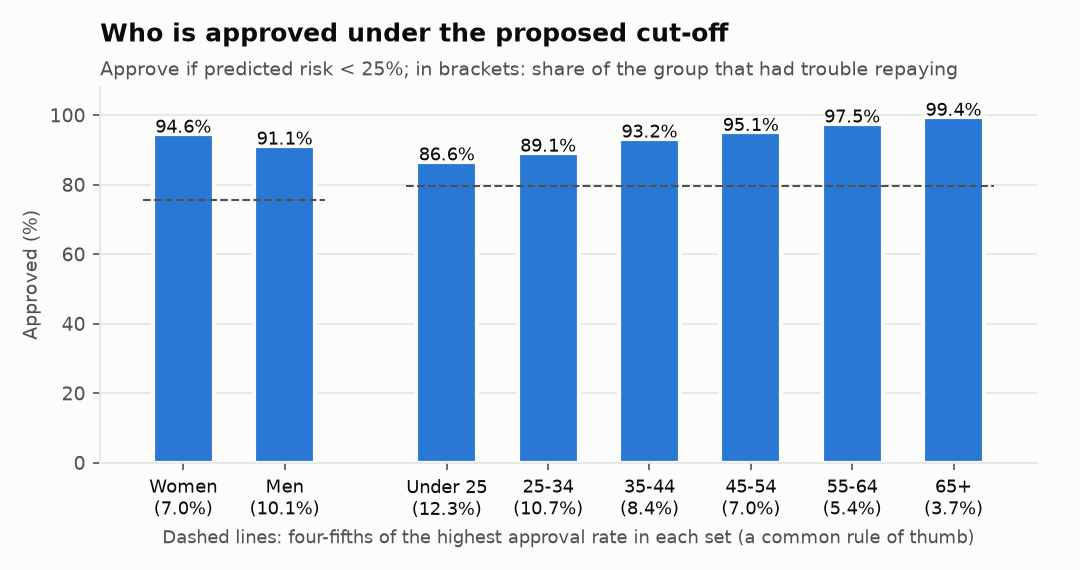

In [19]:
display(pd.read_csv(R / "business_v3m" / "policy_groups.csv").query("model == @FINAL"))
show(figures.approval_by_group(P))

## 13. Technical details
- **Code layout:** `homecredit/` holds the shared code (paths, data loading, the one evaluation module
  `evaluate.py`, model code in `models/`, charts in `figures.py`); `eda/`, `pipeline/` (data, feature tables,
  model training, submissions), `experiments/` (noise, paired comparisons, tuning, monotone check, Kaggle check,
  duplicate check, reproducibility) and `analysis/` (calibration, reason codes, global SHAP, error analysis,
  fairness, proxies, business, credit tables, charts). Scripts run as modules from the repository root, e.g.
  `.venv/bin/python -m pipeline.make_features`. `run_all.sh` runs v1 and v2; `run_v3.sh` runs v3 up to the final
  model and its analyses.
- **Final model:** LightGBM on feature table v3c (`pipeline/make_features_v3.py --fixed` plus
  `pipeline/make_features_rate.py`), candidate groups `win, stk, term, agg, last, trend, load, rate`, without gender,
  family status, the bureau's monthly history and 12 other columns that separate test from train (bureau instalment amounts
  and closing dates, and 2 debt-burden ratios built on them);
  in-fold SHAP selection keeping 90% of the total mean |SHAP|; settings from `analysis_output/tuning/v3b_sh90_best.json`
  (num_leaves 30, min_child_samples 174, feature_fraction 0.24, lambda_l2 6.7); monotone constraints from
  `pipeline/monotone_v3.json` (method "intermediate"); learning rate 0.02, early stopping on an inner 10% of each
  training fold, average of 3 fits.
- **Adoption rule:** paired comparison on the same folds (`experiments/compare.py`); gain more than 2 x the bootstrap
  standard error of the gain (one seed's out-of-fold predictions, 200 resamples) and at least 18 of 25 wins (15 of
  20 when seed 1 chose the setting). Exploratory one-seed runs compare 5 folds and need 4 of 5 wins before a
  5-seed confirmation.
- **Reason codes:** SHAP values of the 3 averaged models are averaged in log-odds, while the prediction averages
  probabilities (a small mismatch). The counterfactual swaps a whole reason group with a random approved applicant's
  values (5 donors), so it tests faithfulness to the model, not real-world causes. The 5 loan-price columns count
  as "Loan size and terms vs income".
- **For scale (Kaggle leaderboard, not a script):** the competition's winning team scored 0.806 on the private
  leaderboard with, by its public write-up, hundreds to thousands of features and about 90 stacked models.
- **Reproducibility:** `run_all.sh` and `run_v3.sh` rerun into a separate folder (about 11 hours) and compared
  file by file with `experiments/check_reproduced.py` (`analysis_output/reproducibility/v3_full_rerun.csv`). Of
  443 files in both runs, 400 match byte for byte and 34 apart from their run-time columns. The other 9: the v3b
  drift check (`adversarial_v3b.parquet` and its two summaries; adversarial AUC 0.98236 vs 0.98237, cause not
  checked, read by no later step) and 6 files that list hand-made runs (4 submission manifests, 2 model
  summaries). Files only in the saved results: the first v3 try (`FIRST_TRY=1`), the runs in `OUTPUTS.md` "Run by
  hand", the Kaggle scores typed by hand and superseded first-version files. The earlier v2-only rerun:
  `v2_full_rerun.csv`.

## 14. Limits
- The target's exact definition (X days late on one of the first Y instalments) is not disclosed.
- Validation uses random folds; there is no time order in the data.
- Only previously approved loans are in the data; the profit numbers are a back-test with assumed margins and losses.
- Only LightGBM was tuned; the other families used common settings.
- The direct age and gender test was measured on the untuned v3 setting, not on the final model.
- The loan-price gain on Kaggle's hidden test was smaller than in validation (section 6).
- If Home Credit priced loans by risk, the estimated rate partly carries the lender's earlier risk view; a new
  pricing policy would change what it means.
- The SHAP cut, tuning, loan price and monotone rule were all judged on the same 25 folds, so the final validation
  score may be a little optimistic; most of the gap to Kaggle appeared at the loan-price step (section 6).
- The business back-test uses the same 20% margin for every loan, although declined loans tend to be dearer; a
  flat margin likely overstates the gain from declining (not measured).
- The target is early payment difficulty with an undisclosed threshold, not a regulatory default definition.
- The test set is a different mix of loans; without dates I cannot tell whether it is also a later period.
- Possible repeat applicants: grouped folds did not lower the score (section 10).